# Lesson 12 · Simulating replications: when does empirical Bayes fail?

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 13 (pp. 130–141)

**Question:** One simulation could be a lucky draw. Does empirical Bayes work *consistently*, and how many observations do you need before you can trust it?

**Goal:** Repeat Lesson 11's simulation 50 times, then vary the number of players from 30 to 10,000 and see where the method breaks down, and why.

**Contents**

1. Setup
2. 50 replications
3. Are the hyperparameters estimated well?
4. Accuracy, coverage and FDR across replications
5. Varying the number of players
6. Why small samples go wrong
7. Exercises

**Tags:** `simulation` `replication` `sample-size` `calibration` `hyperparameter-uncertainty` `robustness`

**Before you start:** Lesson 11. This lesson runs a few hundred fits, so add progress printing to your loops; each fit should take well under a second.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [1]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

%load_ext autoreload
%autoreload 2
import time
try:
    import my_eb   # your toolkit from Lesson 10
except ImportError:
    print("my_eb.py not found: finish Lesson 10, or define the functions you need below.")
  
career = eb_data.career(pitcher_rule=3)[["playerID", "H", "AB"]]
print(f"{len(career):,} players")

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
my_eb.py not found: finish Lesson 10, or define the functions you need below.
13,446 players


## 1. Setup

**12.1.1 · Your turn.** Fit the prior to all players and store the true `alpha0`, `beta0` and mean for the simulations.

In [2]:
# 12.1.1 · Your code here
if "name" not in career:
    career = eb_data.player_names()[["playerID", "name"]].merge(career, on="playerID")

def neg_log_lik(params, H, AB):
    log_a, log_b = params       
    a, b = np.exp(log_a), np.exp(log_b)
    bbsum = stats.betabinom.logpmf(H, AB, a, b).sum()
    return -bbsum             

res = optimize.minimize(neg_log_lik, x0=np.log([1, 10]), args=(career.H, career.AB), method="Nelder-Mead")
alpha0, beta0 = np.exp(res.x)
mean0 = (alpha0 / (alpha0 + beta0))
print(alpha0, beta0, mean0)

66.67350186171704 200.2543620457619 0.24978097410177846


## 2. 50 replications

A tidy way to replicate: stack 50 copies of the players with a `replication` column (`pd.concat` or a cross merge), simulate p and H for all rows at once, then `groupby("replication")` to fit each one.

**12.2.1 · Your turn.** Simulate 50 replications. Fit a prior in each, printing progress (for example every 10 replications, with the elapsed time). Collect `alpha`, `beta` and `mean` per replication.

In [3]:
# 12.2.1 · Your code here
num_reps = 50
reps = []
hypers = []

start_time = time.perf_counter()
for i in range(1, num_reps+1):
    copy = career.copy()
    copy['replication'] = i
    copy['sim_p'] = rng.beta(alpha0, beta0, size = len(copy))
    copy['sim_H'] = rng.binomial(copy.AB, copy.sim_p)
            
    res = optimize.minimize(neg_log_lik, x0=np.log([1, 10]), args=(copy.sim_H, copy.AB), method="Nelder-Mead")
    a_rep, b_rep = np.exp(res.x)
    mean_rep = (a_rep / (a_rep + b_rep))
    
    reps.append(copy)    
    hypers.append({"replication": i, "alpha": a_rep, "beta": b_rep, "mean": mean_rep})
    
    if (i % 10) == 0:
        rep_time = time.perf_counter()
        print(f"Completed {i} replications. Elapsed time: {rep_time - start_time:.2f} sec")

hypers = pd.DataFrame(hypers)
career_sim = pd.concat(reps, axis=0, ignore_index=True)
career_sim.head(20)

Completed 10 replications. Elapsed time: 12.66 sec
Completed 20 replications. Elapsed time: 25.77 sec
Completed 30 replications. Elapsed time: 37.44 sec
Completed 40 replications. Elapsed time: 48.62 sec
Completed 50 replications. Elapsed time: 60.02 sec


,playerID,name,H,AB,replication,sim_p,sim_H
0,aaronha01,Hank Aaron,3771,12364,1,0.2651,3295
1,aaronto01,Tommie Aaron,216,944,1,0.2175,185
2,abadan01,Andy Abad,2,21,1,0.2994,6
3,abadijo01,John Abadie,11,49,1,0.2865,13
4,abbated01,Ed Abbaticchio,772,3044,1,0.2738,816
5,abbeych01,Charlie Abbey,493,1756,1,0.2314,388
6,abbotda01,Dan Abbott,1,7,1,0.2508,2
7,abbotfr01,Fred Abbott,107,513,1,0.2650,141
8,abbotje01,Jeff Abbott,157,596,1,0.2403,139
9,abbotji02,Jim Abbott,0,4,1,0.2213,2


## 3. Are the hyperparameters estimated well?

**12.3.1 · Your turn.** Plot the 50 estimates of α₀, β₀ and the mean (strip or box plots), with the true values as dashed lines.

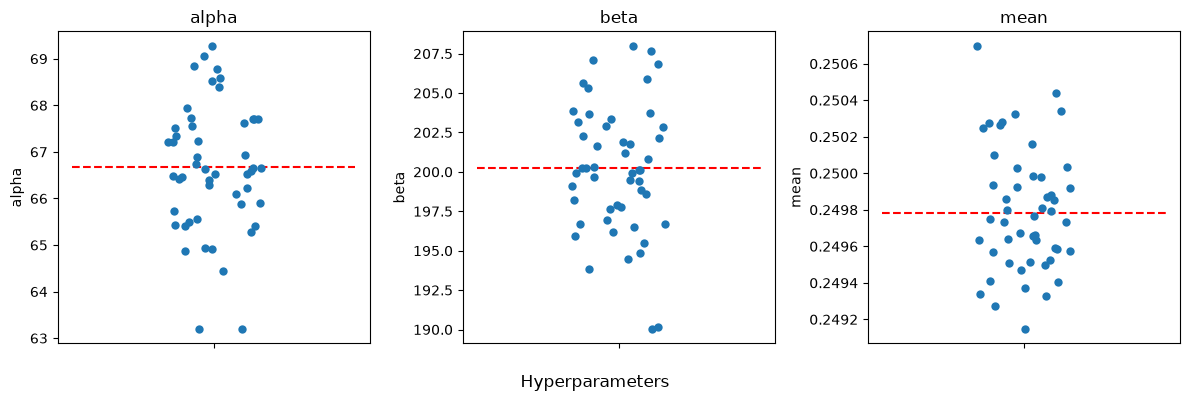

In [4]:
# 12.3.1 · Your code here
import seaborn as sns

trues = [alpha0, beta0, mean0]
fig, axes = plt.subplots(1, 3, figsize = (12, 4))
ys = ['alpha', 'beta', 'mean']
for i, y in zip(range(len(ys)), ys):
    sns.stripplot(data=hypers, y = y, dodge=True, jitter=True, size = 6, ax=axes[i])
    axes[i].set_title(y)
    axes[i].hlines(trues[i], xmin = -0.3, xmax = 0.3, color = 'red', linestyle = '--')
fig.supxlabel("Hyperparameters")
plt.tight_layout()
plt.show()

> **Check:** the estimated means cluster tightly around the true mean (≈ 0.251).

## 4. Accuracy, coverage and FDR across replications

**12.4.1 · Your turn.** For each replication, compute the MSE of raw and shrunken estimates, and plot the two distributions.

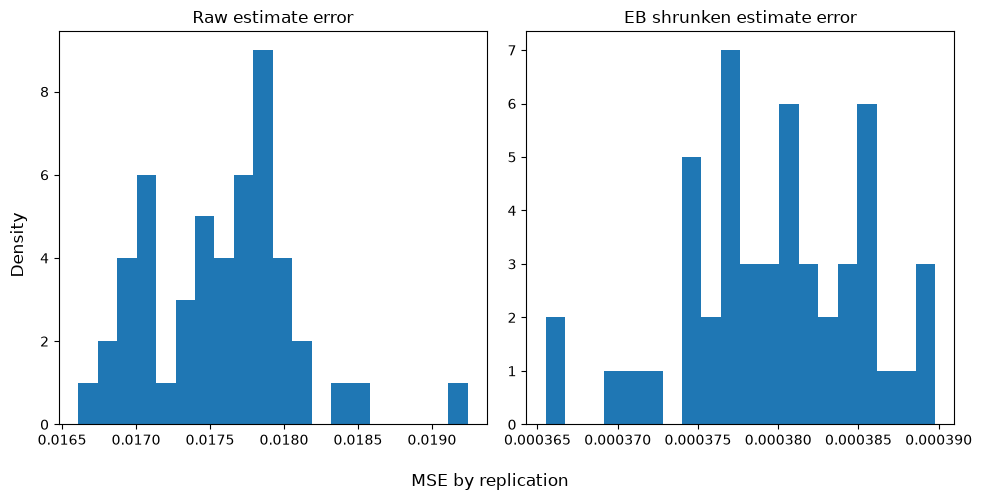

In [5]:
# 12.4.1 · Your code here
if "alpha" not in career_sim:
    career_sim = career_sim.merge(hypers[["replication", "alpha", "beta"]], on="replication")

career_sim["a1_sim"] = career_sim.alpha + career_sim.sim_H
career_sim["b1_sim"] = career_sim.beta + career_sim.AB - career_sim.sim_H
career_sim['raw_sim'] = career_sim.sim_H / career_sim.AB
c

g = career_sim.groupby('replication')

fig, axes = plt.subplots(1, 2, figsize = (10, 5))
axes[0].hist(g['sqerr_raw'].mean(), bins = 20)
axes[1].hist(g['sqerr_EB'].mean(), bins = 20)
axes[0].set_title("Raw estimate error")
axes[1].set_title("EB shrunken estimate error")
fig.supxlabel("MSE by replication")
fig.supylabel("Density")
plt.tight_layout()
plt.show()

**12.4.2 · Your turn.** For each replication, compute the coverage of 95% intervals (histogram), then coverage curves for levels 0.5–0.95: one faint line per replication, plus y = x.

In [6]:
# 12.4.2 · Your code here
def inlevel(pct, df):
    level = pct / 100
    lower = stats.beta(df.a1_sim, df.b1_sim).ppf((1 - level)/2)
    upper =  stats.beta(df.a1_sim, df.b1_sim).ppf(1 - (1 - level)/2)
    return df.sim_p.between(lower, upper).mean()

cov95 = []
props = []

for i in np.arange(1, g.ngroups + 1):
    rep = g.get_group(i)
    for pct in np.arange(50, 99):
        prop = inlevel(pct, rep)
        props.append({"replication": i, "cred": pct/100, "P": prop})
        if pct == 95:
            cov95.append(prop)
        print(f"\rProcessing Replication {i}, level: {pct/100}", end="")

props = pd.DataFrame(props)

Processing Replication 50, level: 0.98

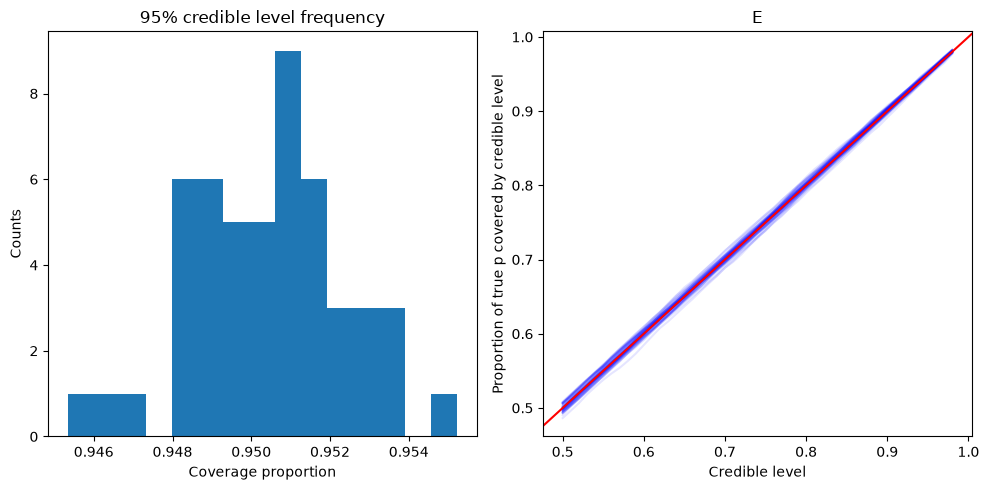

In [7]:
fig, axes = plt.subplots(1, 2, figsize = (10, 5))
axes[0].hist(cov95, bins = 15)
axes[0].set_title("95% credible level frequency")
axes[0].set_xlabel("Coverage proportion")
axes[0].set_ylabel("Counts")

for i in np.arange(1, g.ngroups + 1):
    rep = props[props.replication == i]
    axes[1].plot(rep.cred, rep.P, color = 'blue', alpha = 0.1)
axes[1].axline((0.5, 0.5), slope=1, color = 'red')
axes[1].set_title("E")
axes[1].set_xlabel('Credible level')
axes[1].set_ylabel('Proportion of true p covered by credible level')

plt.tight_layout()
plt.show()

> **Check:** 95% coverage stays roughly between 94.4% and 95.5% across replications.

**12.4.3 · Your turn.** For each replication, run your proportion test against .300 (as in 11.5), then plot the true false discovery proportion against the q-value threshold, one faint line each.

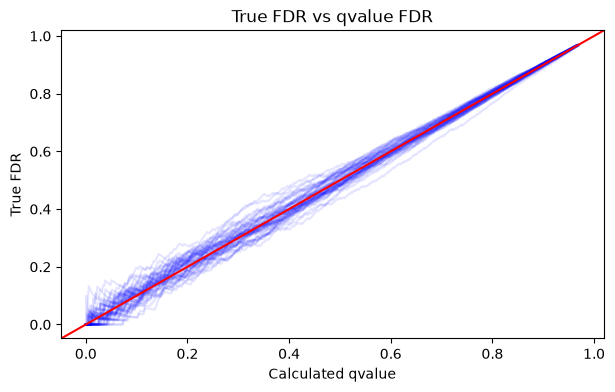

In [9]:
# 12.4.3 · Your code here
career_sim['PEP'] = stats.beta(career_sim.a1_sim, career_sim.b1_sim).cdf(0.3)
career_sim = career_sim.sort_values(by = ["replication", "PEP"], ignore_index = True)

g = career_sim.groupby("replication")
n = g.cumcount() + 1

career_sim["qvalue"] = g["PEP"].cumsum() / n
career_sim["false_disc"] = career_sim.sim_p < 0.3
career_sim["true_fdr"] = career_sim.groupby("replication")["false_disc"].cumsum() / n

for i in np.arange(1, g.ngroups + 1):
    rep = g.get_group(i)
    plt.plot(rep.qvalue, rep.true_fdr, color = 'blue', alpha = 0.1)
plt.axline((0.5, 0.5), slope=1, color = 'red')
plt.title("True FDR vs qvalue FDR")
plt.xlabel("Calculated qvalue")
plt.ylabel("True FDR")
plt.show()

**12.4.4 · Reflect.** FDR control promises the *expected* proportion, not the proportion in every run. What do your FDR curves show?

*12.4.4 · Your answer:*

## 5. Varying the number of players

**12.5.1 · Your turn.** For sizes 30, 100, 300, 1,000, 3,000 and 10,000, with 50 replications each, sample that many players' AB (with replacement), simulate p and H, and fit a prior. Print progress per size, and store the fitted priors along with each replication's MSE and 95% coverage.

In [24]:
# 12.5.1 · Your code here
sizes = [30, 100, 300, 1000, 3000, 10000]
num_reps = 50
career_sizes = []
for size in sizes:
    for i in range(1, num_reps+1):
        players = career.sample(n= size, replace = True)
        players['sim_p'] = rng.beta(alpha0, beta0, size = len(players))
        players['sim_H'] = rng.binomial(players.AB, players.sim_p)
            
        res = optimize.minimize(neg_log_lik, x0=np.log([40, 120]), args=(players.sim_H, players.AB), method="Nelder-Mead")
        a_rep, b_rep = np.exp(res.x)
        
        players['sim_EB'] = (a_rep + players.sim_H) / (a_rep + b_rep + players.AB)
        
        mse = np.mean((players.sim_EB - players.sim_p) ** 2)
        dist = stats.beta((a_rep + players.sim_H), (b_rep + players.AB - players.sim_H))
        cov = players.sim_p.between(dist.ppf(0.025), dist.ppf(0.975)).mean()
        
        career_sizes.append({"size": size, "replication": i, "alpha": a_rep, "beta": b_rep, "mse": mse, "cov95": cov})
        
        print(f"\rCompleted replication {i} for size {size}", end = "")
    print(f"\nCompleted reps for size {size}")

career_sizes = pd.DataFrame(career_sizes)
career_sizes.head()

Completed replication 50 for size 30
Completed reps for size 30
Completed replication 50 for size 100
Completed reps for size 100
Completed replication 50 for size 300
Completed reps for size 300
Completed replication 50 for size 1000
Completed reps for size 1000
Completed replication 50 for size 3000
Completed reps for size 3000
Completed replication 50 for size 10000
Completed reps for size 10000


,size,replication,alpha,beta,mse,cov95
0,30,1,90.5258,274.2238,0.0005,0.9000
1,30,2,86.0497,268.7613,0.0004,0.9333
2,30,3,86.1485,248.3391,0.0003,0.9000
3,30,4,62.7299,180.2967,0.0006,0.9667
4,30,5,178.5065,510.6039,0.0003,0.8667


**12.5.2 · Your turn.** Plot the hyperparameter estimates, MSE and coverage by size (box plots with log-spaced sizes).

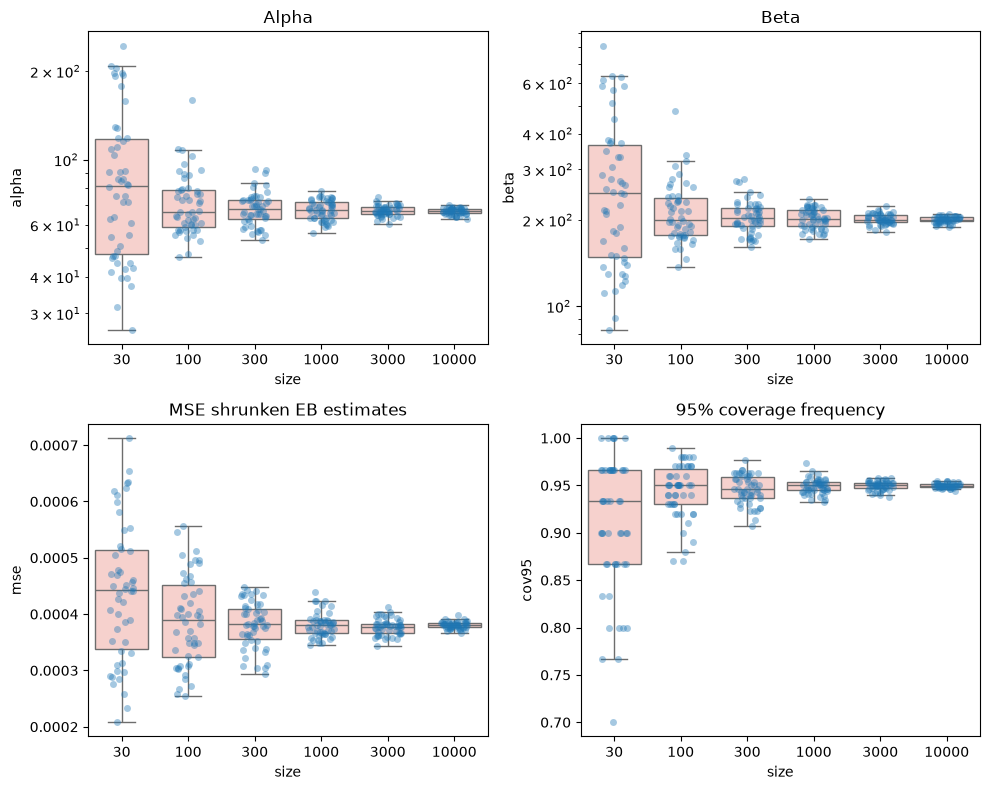

In [30]:
# 12.5.2 · Your code here

titles = ['Alpha', 'Beta', 'MSE shrunken EB estimates', '95% coverage frequency']
data = ['alpha', 'beta', 'mse', 'cov95']
fig, axs = plt.subplots(2, 2, figsize =(10, 8))

for ax, d, title in zip(axs.flat, data, titles):
    sns.stripplot(data = career_sizes, x = 'size', y = d, jitter=0.2, dodge=True, alpha = 0.4, ax = ax)
    bp = sns.boxplot(data = career_sizes, x = 'size', y = d, showfliers = False, color = 'salmon', ax = ax)
    for patch in bp.patches:
        r, g, b, a = patch.get_facecolor()
        patch.set_facecolor((r, g, b, 0.4))  # set alpha to 0.4
    ax.set_title(title)
    if d in ['alpha', 'beta']:
        ax.set_yscale("log")
plt.tight_layout()
plt.show()
        

**12.5.3 · Reflect.** Based on your plots, what's the smallest number of observations you'd be comfortable running empirical Bayes on? Why does the *spread* of the MSE matter more than its average when you only get one real dataset?

*12.5.3 · Your answer:*

## 6. Why small samples go wrong

The prior's spread is controlled by $\alpha_0 + \beta_0$: the larger the sum, the narrower the prior. Overestimate it and you over-shrink, so the intervals come out too narrow.

**12.6.1 · Your turn.** Plot each replication's estimated α₀ + β₀ (log x) against its 95% coverage, one color per size, with a vertical line at the true value. Find the worst replication and look at its data.

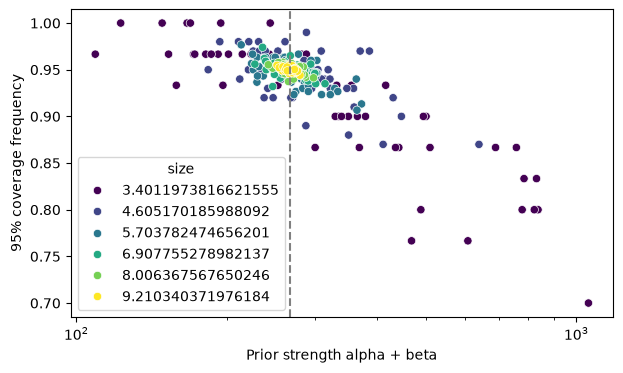

In [45]:
# 12.6.1 · Your code here
sns.scatterplot(x = career_sizes.alpha + career_sizes.beta, y = career_sizes.cov95, hue = np.log(career_sizes['size']), palette = 'viridis')
plt.axvline(alpha0 + beta0, ls="--", color="gray")
plt.xscale("log")
plt.xlabel("Prior strength alpha + beta")
plt.ylabel("95% coverage frequency")
plt.show()

**12.6.2 · Reflect.** What does this show about the main weakness of empirical Bayes, the plug-in prior? How would a full Bayesian model treat the same 30 players differently? (That's Lesson 13.)

*12.6.2 · Your answer:*

## 7. Exercises

**12.7.1 · Your turn.** Halve every player's AB before simulating. How do MSE and coverage change?

In [13]:
# 12.7.1 · Your code here

**12.7.2 · Your turn.** **Card connection.** Pokémon cards are released in *sets*, and there have only been about 100–200 of them. Each set has its own *pull rate*, the chance that a sealed booster pack contains a rare card (a *hit*), and collectors estimate it from the packs they open and log: a few dozen for an obscure set, a few hundred for a popular one. Using these results, would you trust empirical Bayes for set-level pull rates? Simulate 120 sets with realistic packs-opened counts to find out.

In [14]:
# 12.7.2 · Your code here

## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 13.
- Carlin & Louis, *Bayesian Methods for Data Analysis* (3rd ed.), Chapter 5: empirical Bayes and its corrections.